In [1]:
# Cell 1 - run information (required)
import os, subprocess, sys, random, numpy as np, torch
# Locate the repo: run from a local clone, or clone the tagged commit on Kaggle/Colab.
REPO_URL = os.environ.get("REPO_URL", "https://github.com/shulamite512/DATA266_LAB2_PAIR44.git")  # EDIT
GIT_REF = os.environ.get("GIT_REF", "p2-v1.0")
if os.path.isdir("../../src"):  # notebooks/<member>/
    os.chdir("../..")
elif os.path.isdir("../src"):
    os.chdir("..")
import glob, shutil
zips = sorted(glob.glob("/content/**/L2_colab*.zip", recursive=True)
              + glob.glob("/kaggle/input/**/L2_colab*.zip", recursive=True), key=os.path.getmtime)
if not os.path.isdir("src") and zips:  # uploaded project zip (newest one wins)
    dest = "/content" if zips[-1].startswith("/content") else "/kaggle/working/l2"
    print("using", zips[-1], "->", dest)
    subprocess.run(["unzip", "-q", "-o", zips[-1], "-d", dest], check=False)
    os.chdir(dest)
kaggle_src = glob.glob("/kaggle/input/**/src/p1", recursive=True)
if not os.path.isdir("src") and kaggle_src:  # Kaggle dataset made from the zip (Kaggle auto-extracts it)
    root = os.path.dirname(os.path.dirname(kaggle_src[0]))
    print("using Kaggle dataset", root)
    shutil.copytree(root, "/kaggle/working/l2", dirs_exist_ok=True)
    os.chdir("/kaggle/working/l2")
if not os.path.isdir("src") and "YOUR_GITHUB" in REPO_URL:
    raise SystemExit("Project code not found: upload L2_colab.zip to /content (Files pane -> content -> Upload), "
                     "wait for the upload to finish, then run this cell again.")
if not os.path.isdir("src"):
    url = REPO_URL
    try:
        from kaggle_secrets import UserSecretsClient
        url = REPO_URL.replace("https://", "https://" + UserSecretsClient().get_secret("GITHUB_TOKEN") + "@")
    except Exception:
        try:
            from google.colab import userdata
            url = REPO_URL.replace("https://", "https://" + userdata.get("GITHUB_TOKEN") + "@")
        except Exception:
            pass
    subprocess.run(["git", "clone", "--quiet", url, "/tmp/repo"], check=True)
    subprocess.run(["git", "-C", "/tmp/repo", "remote", "set-url", "origin", REPO_URL], check=True)  # drop token
    subprocess.run(["git", "-C", "/tmp/repo", "checkout", "--quiet", GIT_REF], check=True)
    os.chdir("/tmp/repo")
sys.path.insert(0, os.getcwd())
res = subprocess.run([sys.executable, "-m", "src.common.install"], capture_output=True, text=True)
print(res.stdout[-4000:], res.stderr[-4000:])
assert res.returncode == 0, "dependency install failed - see the pip output above"
from src.common.runinfo import library_versions
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})
print(library_versions())

using /content/L2_colab.zip -> /content
installed (pinned): transformers==4.51.3, accelerate==1.2.1, diffusers==0.32.2, peft==0.14.0, huggingface_hub==0.30.2, datasets==3.2.0, safetensors==0.4.5, bitsandbytes==0.48.2, sentence-transformers==3.3.1, rank-bm25==0.2.2, chromadb==1.0.12, pymupdf==1.25.1, torchmetrics==1.6.0, torch-fidelity==0.3.0, lpips==0.1.4, gradio==5.29.0
 
{'commit': '', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'gpu': 'Tesla T4', 'seed': 266}
{'transformers': '4.51.3', 'diffusers': '0.32.2', 'peft': '0.14.0', 'accelerate': '1.2.1', 'sentence_transformers': '3.3.1', 'chromadb': '1.0.12', 'fitz': '1.25.1', 'rank_bm25': '?', 'torchmetrics': '1.6.0', 'lpips': '?', 'gradio': '5.29.0', 'datasets': '3.2.0'}


# Part 2 - Fine-tuning Stable Diffusion 1.5 with LoRA (Naruto BLIP captions)

In [2]:
import os
from huggingface_hub import login
tok = os.environ.get("HF_TOKEN")
if not tok:
    try:
        from kaggle_secrets import UserSecretsClient; tok = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        try:
            from google.colab import userdata; tok = userdata.get("HF_TOKEN")
        except Exception:
            tok = None
if tok:
    login(token=tok)
else:
    print("No HF_TOKEN found: uploads will fail (generation still works).")

In [3]:
import json, pandas as pd
from src.p2 import config as C
from src.p2.data_prep import prepare, write_prompts, load_split
report = prepare()
print(json.dumps(report, indent=1))

README.md: 0.00B [00:00, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/897 [00:00<?, ?B/s]

data/train-00000-of-00002-12944970063701(…):   0%|          | 0.00/344M [00:00<?, ?B/s]

data/train-00001-of-00002-cefa2f480689f1(…):   0%|          | 0.00/357M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1221 [00:00<?, ? examples/s]

{
 "source": "lambdalabs/naruto-blip-captions",
 "raw": 1221,
 "corrupted": 0,
 "missing_caption": 0,
 "exact_duplicates": 0,
 "near_duplicates": 0,
 "kept": 1221,
 "removed_total": 0,
 "n_test": 122,
 "n_train": 1099,
 "caption_words_mean": 8.93,
 "caption_words_min_max": [
  6,
  41
 ],
 "orig_sizes_top": [
  [
   "1080x1080",
   468
  ],
  [
   "1076x1076",
   135
  ],
  [
   "1620x1620",
   33
  ]
 ]
}


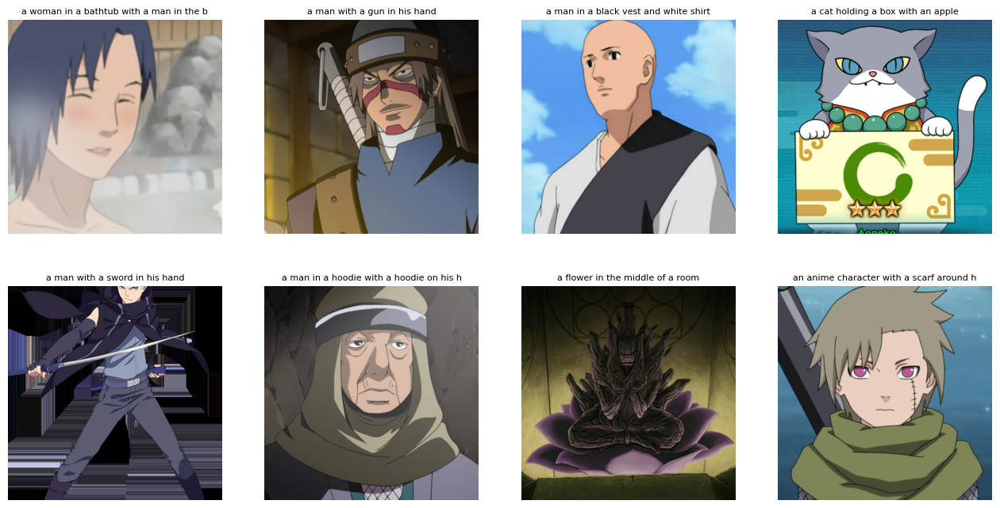

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
train_items = load_split("train"); test = load_split("test")
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (p, c) in zip(axes.flat, train_items[:8]):
    ax.imshow(Image.open(p)); ax.set_title(c[:40], fontsize=8); ax.axis("off")
plt.show()

**Dataset description** (edit in your own words): ~1.2k Naruto anime frames with BLIP captions ...
Limitations/biases: (1) BLIP captions are short and generic and often wrong about characters; (2) mostly close-up
faces of a few main characters, so poses, backgrounds and diversity of people are limited.

In [5]:
prompts = write_prompts()   # 10 in-domain from TEST captions + 5 OOD + 5 compositional
print(json.dumps(prompts, indent=1))
print("-> commit prompts/p2_prompts.json BEFORE training finishes")

[
 {
  "id": "in_00",
  "category": "in_domain",
  "prompt": "a man with long hair and black hair",
  "test_image": "test_0008.png"
 },
 {
  "id": "in_01",
  "category": "in_domain",
  "prompt": "a man with a sword in his hand",
  "test_image": "test_0069.png"
 },
 {
  "id": "in_02",
  "category": "in_domain",
  "prompt": "a woman with long hair and a mask on her face",
  "test_image": "test_0087.png"
 },
 {
  "id": "in_03",
  "category": "in_domain",
  "prompt": "a woman with a gun in her hand",
  "test_image": "test_0086.png"
 },
 {
  "id": "in_04",
  "category": "in_domain",
  "prompt": "a girl in a red coat sitting on the ground",
  "test_image": "test_0012.png"
 },
 {
  "id": "in_05",
  "category": "in_domain",
  "prompt": "a group of people sitting on the ground",
  "test_image": "test_0057.png"
 },
 {
  "id": "in_06",
  "category": "in_domain",
  "prompt": "a man in a white shirt and a black shirt",
  "test_image": "test_0094.png"
 },
 {
  "id": "in_07",
  "category": "in_domain

## 2.2 Two runs, same data and step budget (LoRA rank 8 vs rank 32)

In [6]:
from src.p2.train_lora import train
stats = {}
for name, kw in C.RUNS.items():
    stats[name] = train(name, **kw, **C.TRAIN_COMMON)

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

... (3 outputs left out)

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

/content/src/p2/train_lora.py:76: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


[run1_lora_r8] step 1/1500 loss 0.0498 lr 1.00e-06 5s
[run1_lora_r8] step 50/1500 loss 0.0910 lr 5.00e-05 81s
[run1_lora_r8] step 100/1500 loss 0.1034 lr 1.00e-04 161s
[run1_lora_r8] step 150/1500 loss 0.0844 lr 9.97e-05 241s
[run1_lora_r8] step 200/1500 loss 0.1010 lr 9.87e-05 320s
[run1_lora_r8] step 250/1500 loss 0.0890 lr 9.72e-05 401s
[run1_lora_r8] step 300/1500 loss 0.0790 lr 9.50e-05 481s
[run1_lora_r8] step 350/1500 loss 0.0966 lr 9.23e-05 561s
[run1_lora_r8] step 400/1500 loss 0.0906 lr 8.91e-05 640s
[run1_lora_r8] step 450/1500 loss 0.0852 lr 8.54e-05 720s
[run1_lora_r8] step 500/1500 loss 0.0811 lr 8.12e-05 799s
[run1_lora_r8] step 550/1500 loss 0.1085 lr 7.66e-05 879s
[run1_lora_r8] step 600/1500 loss 0.0920 lr 7.17e-05 960s
[run1_lora_r8] step 650/1500 loss 0.0961 lr 6.65e-05 1039s
[run1_lora_r8] step 700/1500 loss 0.0923 lr 6.11e-05 1119s
[run1_lora_r8] step 750/1500 loss 0.0870 lr 5.56e-05 1199s
[run1_lora_r8] step 800/1500 loss 0.0890 lr 5.00e-05 1279s
[run1_lora_r8] s

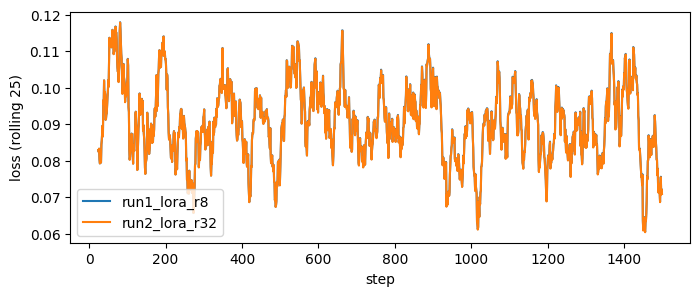

,method,rank,trainable_params,learning_rate,steps,effective_batch,batch_size,grad_accum,peak_gpu_mem_gb,train_seconds,gpu_hours,gpu,final_loss_avg50
run1_lora_r8,LoRA,8,1594368,0.0001,1500,4,2,2,3.68,2396.8,0.666,Tesla T4,0.078539
run2_lora_r32,LoRA,32,6377472,0.0001,1500,4,2,2,3.73,2399.0,0.666,Tesla T4,0.078415


In [7]:
cols = ["method", "rank", "trainable_params", "learning_rate", "steps", "effective_batch", "batch_size", "grad_accum",
        "peak_gpu_mem_gb", "train_seconds", "gpu_hours", "gpu", "final_loss_avg50"]
train_table = pd.DataFrame({k: {c: v[c] for c in cols} for k, v in stats.items()}).T
plt.figure(figsize=(8, 3))
for k, v in stats.items():
    plt.plot(pd.Series(v["losses"]).rolling(25).mean(), label=k)
plt.legend(); plt.xlabel("step"); plt.ylabel("loss (rolling 25)"); plt.show()
train_table

## 2.3 Generation: 20 prompts x seeds {0,1} x {base, run1, run2}

In [8]:
from src.p2.generate import generate_all, side_by_side
MODELS = {"base": None, **{k: os.path.join(C.OUT_DIR, "models", k) for k in C.RUNS}}
meta = generate_all(MODELS, prompts)
print(meta.groupby("model").agg(images=("file", "count"), nsfw_flagged=("nsfw_flagged", "sum"), sec_per_image=("seconds", "median")))

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

safety_checker/model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


               images  nsfw_flagged  sec_per_image
model                                             
base               40             0           4.72
run1_lora_r8       40             2           4.98
run2_lora_r32      40             4           4.99


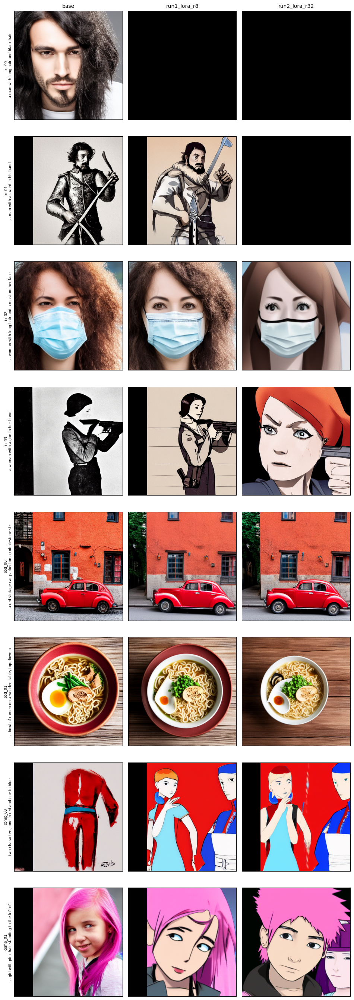

'outputs/p2/grid_8_prompts.png'

In [9]:
grid_ids = ["in_00", "in_01", "in_02", "in_03", "ood_00", "ood_01", "comp_00", "comp_01"]
side_by_side(meta, grid_ids, list(MODELS), os.path.join(C.OUT_DIR, "grid_8_prompts.png"))

## 2.4 Evaluation: KID (in-domain vs test), CLIP score, LPIPS diversity

In [10]:
from src.p2.evaluate import kid, lpips_diversity
from src.common.clip_utils import ClipScorer
clip = ClipScorer()
test_paths = [p for p, _ in test]
rows = []
for m in MODELS:
    sub = meta[meta.model == m]
    ind = sub[sub.category == "in_domain"]
    k_mean, k_std = kid(test_paths, ind.file.tolist())
    cs = clip.clip_score(sub.file.tolist(), sub.prompt.tolist())
    cs_in = clip.clip_score(ind.file.tolist(), ind.prompt.tolist())
    lp, _ = lpips_diversity(meta, m)
    rows.append({"model": m, "KID_in_domain_mean": round(k_mean, 4), "KID_std": round(k_std, 4),
                 "CLIP_score_all40": round(float(np.mean(cs)), 2), "CLIP_score_in_domain": round(float(np.mean(cs_in)), 2),
                 "LPIPS_diversity": round(lp, 4), "nsfw_flagged": int(sub.nsfw_flagged.sum())})
eval_table = pd.DataFrame(rows).set_index("model")
eval_table

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/599M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

... (4 outputs left out)

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)  # noqa: B028
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth

  0%|          | 0.00/91.2M [00:00<?, ?B/s]
  0%|          | 384k/91.2M [00:00<00:31, 3.05MB/s]
  1%|          | 768k/91.2M [00:00<00:41, 2.26MB/s]
  1%|          | 1.00M/91.2M [00:00<00:43, 2.16MB/s]
  1%|▏         | 1.25M/91.2M [00:00<00:44, 2.10MB/s]
  2%|▏         | 1.50M/91.2M [00:00<00:46, 2.04MB/s]
  2%|▏         | 1.75M/91.2M [00:00<00:47, 1.98MB/s]
  2%|▏         | 2.00M/91.2M [00:01<00:47, 1.95MB/s]
  2%|▏         | 2.25M/91.2M [00:01<00:48, 1.94MB/s]
  3%|▎         | 2.50M/91.2M [00:01<00:48, 1.91MB/s]
 

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 165MB/s]
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)  # noqa: B028
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/torchmetrics/

,KID_in_domain_mean,KID_std,CLIP_score_all40,CLIP_score_in_domain,LPIPS_diversity,nsfw_flagged
model,,,,,,
base,0.1030,0.0098,31.50,30.14,0.7187,0
run1_lora_r8,0.0359,0.0058,30.72,28.66,0.7210,2
run2_lora_r32,0.0451,0.0069,30.21,27.15,0.6925,4


Pick the final run from the table above (set `FINAL`).

In [11]:
FINAL = "run1_lora_r8"   # EDIT after looking at the results
from src.p2.evaluate import make_human_pairs, human_win_rate
key = make_human_pairs(meta, FINAL)
print("Raters: open outputs/p2/human_eval/pair_XX.png only (NOT key.csv) and fill eval/p2_human_ratings.csv")
print(human_win_rate(key, "eval/p2_human_ratings.csv", FINAL))

Raters: open outputs/p2/human_eval/pair_XX.png only (NOT key.csv) and fill eval/p2_human_ratings.csv
None


## Failure modes (pick at least two and describe them in the report)

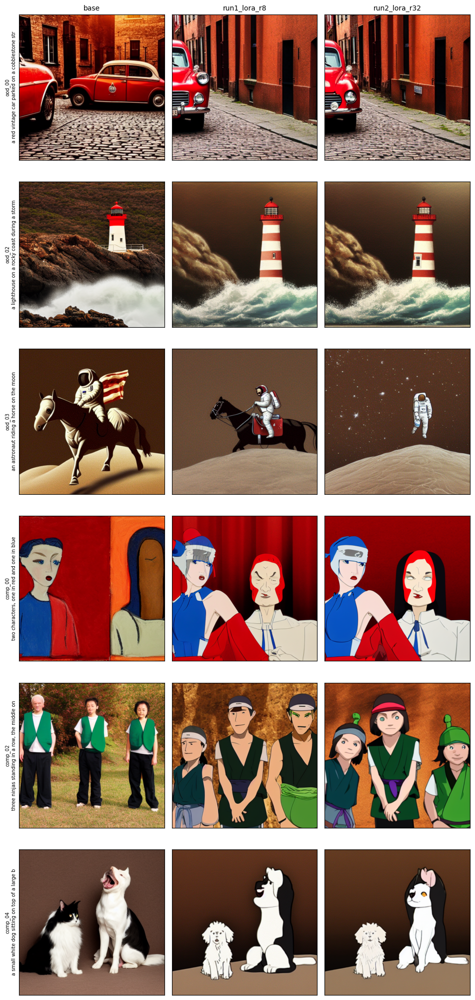

'outputs/p2/failure_modes.png'

In [12]:
side_by_side(meta, ["ood_00", "ood_02", "ood_03", "comp_00", "comp_02", "comp_04"], list(MODELS),
             os.path.join(C.OUT_DIR, "failure_modes.png"), seed=1)

## Safety: memorization check (10 in-domain generations vs all training images, CLIP image similarity)

                                          generated  \
0  outputs/p2/generations/run1_lora_r8/in_07_s0.png   
1  outputs/p2/generations/run1_lora_r8/in_06_s0.png   
2  outputs/p2/generations/run1_lora_r8/in_01_s0.png   
3  outputs/p2/generations/run1_lora_r8/in_09_s0.png   
4  outputs/p2/generations/run1_lora_r8/in_08_s0.png   
5  outputs/p2/generations/run1_lora_r8/in_00_s0.png   
6  outputs/p2/generations/run1_lora_r8/in_03_s0.png   
7  outputs/p2/generations/run1_lora_r8/in_04_s0.png   
8  outputs/p2/generations/run1_lora_r8/in_02_s0.png   
9  outputs/p2/generations/run1_lora_r8/in_05_s0.png   

                  nearest_train  clip_cos  
0  data/p2/train/train_0193.png  0.879275  
1  data/p2/train/train_0648.png  0.831833  
2  data/p2/train/train_0691.png  0.751789  
3  data/p2/train/train_0019.png  0.736533  
4  data/p2/train/train_0316.png  0.731172  
5  data/p2/train/train_0727.png  0.712990  
6  data/p2/train/train_0473.png  0.710931  
7  data/p2/train/train_0754.png  0.673603 

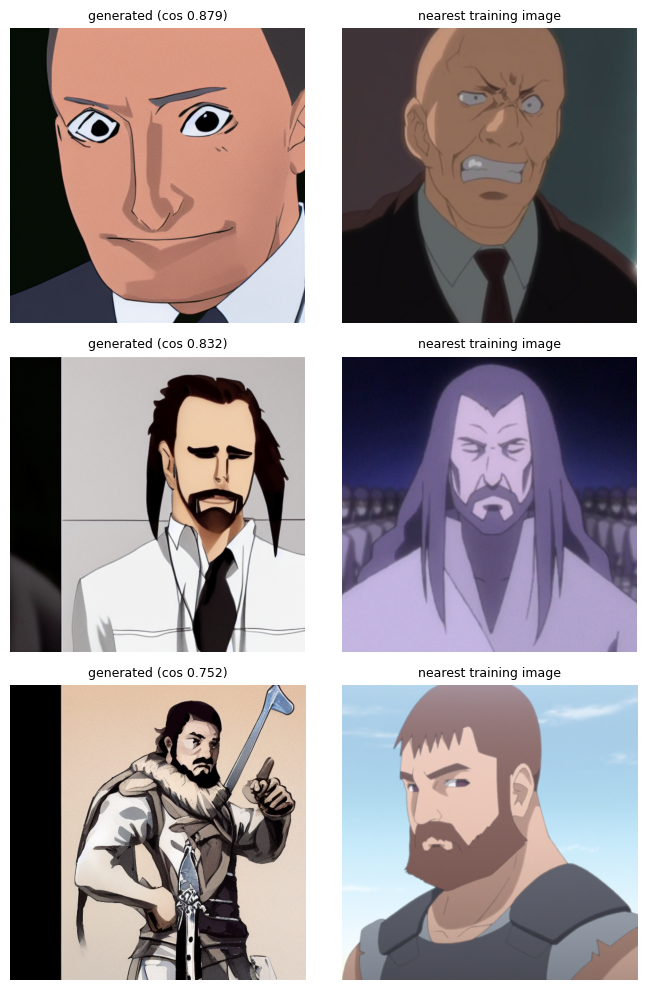

In [13]:
from src.p2.evaluate import memorization
gen10 = meta[(meta.model == FINAL) & (meta.category == "in_domain") & (meta.seed == 0)].file.tolist()
mem_all, top3 = memorization(clip, gen10, [p for p, _ in train_items])
print(mem_all[["generated", "nearest_train", "clip_cos"]])
fig, axes = plt.subplots(3, 2, figsize=(7, 10))
for i, r in top3.iterrows():
    axes[i, 0].imshow(Image.open(r.generated)); axes[i, 0].set_title(f"generated (cos {r.clip_cos:.3f})", fontsize=9)
    axes[i, 1].imshow(Image.open(r.nearest_train)); axes[i, 1].set_title("nearest training image", fontsize=9)
    axes[i, 0].axis("off"); axes[i, 1].axis("off")
plt.tight_layout(); plt.show()

## Results table and Hugging Face upload

In [14]:
hw = human_win_rate(key, "eval/p2_human_ratings.csv", FINAL) or {}
results = eval_table.copy()
for k in C.RUNS:
    results.loc[k, "GPU_hours"] = stats[k]["gpu_hours"]; results.loc[k, "peak_mem_GB"] = stats[k]["peak_gpu_mem_gb"]
results.loc[FINAL, "human_style_win_rate_vs_base"] = hw.get("style_choice_final_win_rate")
results.loc[FINAL, "human_prompt_win_rate_vs_base"] = hw.get("prompt_choice_final_win_rate")
results

,KID_in_domain_mean,KID_std,CLIP_score_all40,CLIP_score_in_domain,LPIPS_diversity,nsfw_flagged,GPU_hours,peak_mem_GB,human_style_win_rate_vs_base,human_prompt_win_rate_vs_base
model,,,,,,,,,,
base,0.1030,0.0098,31.50,30.14,0.7187,0,NaN,NaN,NaN,NaN
run1_lora_r8,0.0359,0.0058,30.72,28.66,0.7210,2,0.666,3.68,None,None
run2_lora_r32,0.0451,0.0069,30.21,27.15,0.6925,4,0.666,3.73,NaN,NaN


In [16]:
import os
from huggingface_hub import login, whoami
try:
    from google.colab import userdata; tok = userdata.get("HF_TOKEN")
except Exception:
    from kaggle_secrets import UserSecretsClient; tok = UserSecretsClient().get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = tok
login(token=tok)
info = whoami(token=tok)
user = info["name"]
print("HF user:", user, "| token role:", info.get("auth", {}).get("accessToken", {}).get("role"))

os.environ["HF_USER"] = user
from src.p2 import config as C
C.HF_USER = user
C.HF_MODEL_REPOS = {n: f"{user}/data266-lab2-naruto-{n.replace('_', '-')}" for n in C.RUNS}
C.HF_IMAGES_REPO = f"{user}/data266-lab2-p2-generations"
print(C.HF_MODEL_REPOS, C.HF_IMAGES_REPO)


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HF user: chels512 | token role: write
{'run1_lora_r8': 'chels512/data266-lab2-naruto-run1-lora-r8', 'run2_lora_r32': 'chels512/data266-lab2-naruto-run2-lora-r32'} chels512/data266-lab2-p2-generations


In [17]:
from src.p2.hub import push_lora, push_images
links = {}
for k in C.RUNS:
    s = stats[k]
    card = None
    if k == FINAL:
        card = dict(base=C.BASE_MODEL, dataset=C.DATASET, run=k, method=s["method"], rank=s["rank"], alpha=s["alpha"],
                    targets=s["target_modules"], train_images=s["train_images"], steps=s["steps"], batch_size=s["batch_size"],
                    grad_accum=s["grad_accum"], lr=s["learning_rate"], schedule=s["lr_schedule"], seed=s["seed"],
                    params=s["trainable_params"], mem=s["peak_gpu_mem_gb"], gpu_hours=s["gpu_hours"], gpu=s["gpu"],
                    results=results.loc[["base", k]].T.to_string())
    links[k] = push_lora(os.path.join(C.OUT_DIR, "models", k), C.HF_MODEL_REPOS[k], card)
links["images"] = push_images(meta, C.HF_IMAGES_REPO)
print(json.dumps(links, indent=1))

Uploading...:   0%|          | 0.00/6.41M [00:00<?, ?B/s]

Uploading...:   0%|          | 0.00/25.5M [00:00<?, ?B/s]

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/120 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Uploading files as bytes or binary IO objects is not supported by Xet Storage. Falling back to HTTP upload.


{
 "run1_lora_r8": "https://huggingface.co/chels512/data266-lab2-naruto-run1-lora-r8",
 "run2_lora_r32": "https://huggingface.co/chels512/data266-lab2-naruto-run2-lora-r32",
 "images": "https://huggingface.co/datasets/chels512/data266-lab2-p2-generations"
}
